<a href="https://colab.research.google.com/github/er1cbrown/BiostatsPython/blob/main/Diabetic_Retinopathy_EDA_APTOS_%2B_EyePACS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [4]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

aptos2019_blindness_detection_path = kagglehub.competition_download('aptos2019-blindness-detection')
tanlikesmath_diabetic_retinopathy_resized_path = kagglehub.dataset_download('tanlikesmath/diabetic-retinopathy-resized')

print('Data source import complete.')


Data source import complete.


# Diabetic Retinopathy Grading: EDA (APTOS 2019 + EyePACS 2015)

Exploratory analysis of the two main public fundus-photo datasets graded on the ICDR **0–4** scale:

| Grade | Meaning |
|---|---|
| 0 | No DR |
| 1 | Mild NPDR |
| 2 | Moderate NPDR |
| 3 | Severe NPDR |
| 4 | Proliferative DR |

**Inputs** (attached to this notebook):
- `aptos2019-blindness-detection` (competition, ~3.7k labeled PNGs)
- `tanlikesmath/diabetic-retinopathy-resized` (EyePACS 2015 train set, ~35k JPEGs, resized)

**What this covers:** label distributions and imbalance, image geometry, the black-border crop, brightness/color differences between datasets, image-quality checks (blur, darkness), patient-level structure in EyePACS (left/right eyes), near-duplicate detection, and a leakage-safe train/val split saved to CSV.

In [5]:
import os, glob, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42; random.seed(SEED); np.random.seed(SEED)

DATA_ROOT = Path(os.environ.get("DATA_ROOT", "/kaggle/input"))
SAMPLE_PER_SOURCE = int(os.environ.get("SAMPLE_PER_SOURCE", 1500))  # images per dataset for pixel-level stats
GRADE_NAMES = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}
PALETTE = {"APTOS": "#2a78b5", "EyePACS": "#d9822b"}
print("Data root:", DATA_ROOT)
for p in sorted(DATA_ROOT.iterdir()): print(" -", p.name)

Data root: /kaggle/input


## 1. Locate files and load labels
Paths are discovered with `glob`, so the notebook still works if the dataset folder names differ slightly.

In [6]:
# Point DATA_ROOT to where kagglehub downloaded the datasets
DATA_ROOT = Path("/root/.cache/kagglehub")

def find_one(pattern):
    hits = sorted(DATA_ROOT.glob(pattern))
    assert hits, f"Nothing matches {pattern} under {DATA_ROOT}"
    return hits[0]

# APTOS
aptos_csv = find_one("**/aptos*/train.csv")
aptos_img_dir = aptos_csv.parent / "train_images"
aptos = pd.read_csv(aptos_csv).rename(columns={"id_code": "image_id", "diagnosis": "grade"})
aptos["path"] = aptos.image_id.map(lambda i: str(aptos_img_dir / f"{i}.png"))
aptos["source"] = "APTOS"
aptos["patient_id"] = aptos.image_id          # APTOS has no patient info
aptos["eye"] = np.nan

# EyePACS: prefer the uncropped label file
label_files = sorted(DATA_ROOT.glob("**/trainLabels*.csv"), key=lambda p: ("cropped" in p.name, len(str(p))))
eyepacs_csv = label_files[0]
eye_imgs = {Path(p).stem: p for p in glob.glob(str(DATA_ROOT / "**/resized_train/**/*.jpeg"), recursive=True)}
if not eye_imgs:
    eye_imgs = {Path(p).stem: p for p in glob.glob(str(eyepacs_csv.parent / "**/*.jpeg"), recursive=True)}
eyepacs = pd.read_csv(eyepacs_csv).rename(columns={"image": "image_id", "level": "grade"})
eyepacs["path"] = eyepacs.image_id.map(eye_imgs)
missing = eyepacs.path.isna().sum()
eyepacs = eyepacs.dropna(subset=["path"])
eyepacs["source"] = "EyePACS"
eyepacs["patient_id"] = eyepacs.image_id.str.rsplit("_", n=1).str[0]
eyepacs["eye"] = eyepacs.image_id.str.rsplit("_", n=1).str[1]

df = pd.concat([aptos, eyepacs], ignore_index=True)[["image_id", "patient_id", "eye", "grade", "source", "path"]]
df["grade"] = df.grade.astype(int)
print(f"APTOS:   {len(aptos):>6,} images  ({aptos_csv})")
print(f"EyePACS: {len(eyepacs):>6,} images  ({eyepacs_csv}); {missing} label rows had no image file")
df.head()

APTOS:    3,662 images  (/root/.cache/kagglehub/competitions/aptos2019-blindness-detection/train.csv)
EyePACS: 35,126 images  (/root/.cache/kagglehub/datasets/tanlikesmath/diabetic-retinopathy-resized/versions/7/trainLabels.csv); 0 label rows had no image file


,image_id,patient_id,eye,grade,source,path
0,000c1434d8d7,000c1434d8d7,NaN,2,APTOS,/root/.cache/kagglehub/competitions/aptos2019-...
1,001639a390f0,001639a390f0,NaN,4,APTOS,/root/.cache/kagglehub/competitions/aptos2019-...
2,0024cdab0c1e,0024cdab0c1e,NaN,1,APTOS,/root/.cache/kagglehub/competitions/aptos2019-...
3,002c21358ce6,002c21358ce6,NaN,0,APTOS,/root/.cache/kagglehub/competitions/aptos2019-...
4,005b95c28852,005b95c28852,NaN,0,APTOS,/root/.cache/kagglehub/competitions/aptos2019-...


## 2. Label distribution and class imbalance

count             %        
source            APTOS EyePACS APTOS EyePACS
0 – No DR          1805   25810  49.3    73.5
1 – Mild            370    2443  10.1     7.0
2 – Moderate        999    5292  27.3    15.1
3 – Severe          193     873   5.3     2.5
4 – Proliferative   295     708   8.1     2.0

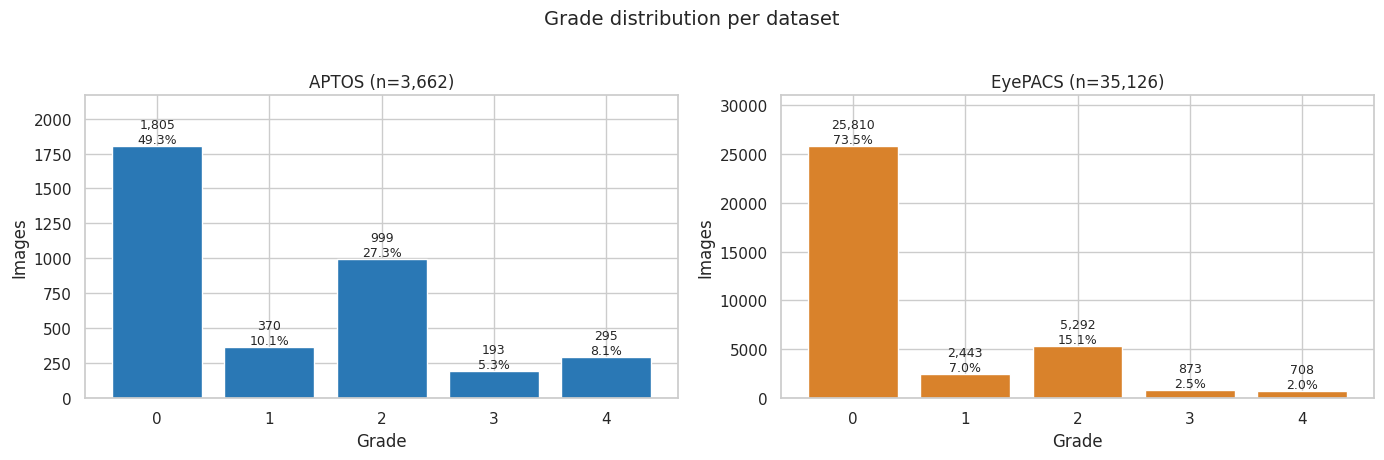

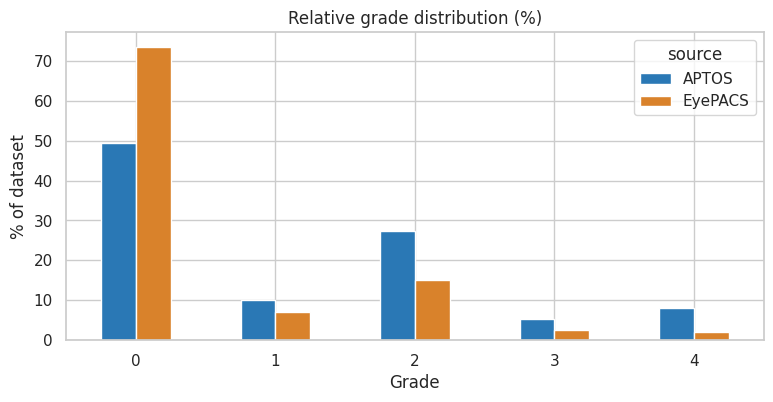

APTOS: majority/minority ratio = 9.4x | referable DR (grade >= 2) = 40.6%
EyePACS: majority/minority ratio = 36.5x | referable DR (grade >= 2) = 19.6%


In [28]:
counts = df.groupby(["source", "grade"]).size().unstack(0).fillna(0).astype(int)
pct = counts / counts.sum() * 100
summary = pd.concat({"count": counts, "%": pct.round(1)}, axis=1)
summary.index = [f"{g} – {GRADE_NAMES[g]}" for g in summary.index]
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (src, sub) in zip(axes, counts.items()):
    bars = ax.bar(sub.index, sub.values, color=PALETTE[src])
    ax.bar_label(bars, labels=[f"{v:,}\n{p:.1f}%" for v, p in zip(sub.values, pct[src])], fontsize=9)
    ax.set(title=f"{src} (n={sub.sum():,})", xlabel="Grade", ylabel="Images", xticks=range(5))
    ax.set_ylim(0, sub.max() * 1.2)
plt.suptitle("Grade distribution per dataset", y=1.02, fontsize=14); plt.tight_layout(); plt.show()

ax = pct.plot(kind="bar", figsize=(9, 4), color=[PALETTE[c] for c in pct.columns], rot=0)
ax.set(title="Relative grade distribution (%)", xlabel="Grade", ylabel="% of dataset"); plt.show()

for src in counts:
    c = counts[src]
    print(f"{src}: majority/minority ratio = {c.max() / c.min():.1f}x | referable DR (grade >= 2) = {c[2:].sum() / c.sum():.1%}")

In [10]:
import os
import cv2
import numpy as np
import pandas as pd
from concurrent.futures import ProcessPoolExecutor   # or ThreadPoolExecutor if ProcessPool gives pickling issues
from tqdm.auto import tqdm

# ---------- sampling (unchanged) ----------
def stratified_sample(d, n):
    out = []
    for g, grp in d.groupby("grade"):
        k = max(1, int(round(n * len(grp) / len(d))))
        out.append(grp.sample(min(k, len(grp)), random_state=SEED))
    return pd.concat(out)

sample = pd.concat(
    [stratified_sample(d, SAMPLE_PER_SOURCE) for _, d in df.groupby("source")],
    ignore_index=True
)

# ---------- stats function ----------
def image_stats(path):
    try:
        img = cv2.imread(path)
        if img is None:
            return {}

        h, w = img.shape[:2]
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Foreground mask (cheap threshold)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        m = gray > 10
        fg_frac = float(m.mean())

        if m.any():
            fg = img[m]
            mean_rgb = fg.mean(axis=0)
            brightness = float(fg.mean())
            contrast = float(fg.std())
        else:
            mean_rgb = [np.nan, np.nan, np.nan]
            brightness = contrast = np.nan

        # Blur on downsampled foreground only
        target_w = 512
        target_h = max(1, int(target_w * h / w))
        small = cv2.resize(gray, (target_w, target_h))
        small_m = cv2.resize(m.astype(np.uint8), (target_w, target_h)) > 0

        if small_m.any():
            lap = cv2.Laplacian(small, cv2.CV_64F)
            blur = float(lap[small_m].var())
        else:
            blur = np.nan

        return dict(
            width=w,
            height=h,
            aspect=w / h,
            file_kb=os.path.getsize(path) / 1024,
            fg_frac=fg_frac,
            mean_r=mean_rgb[0],
            mean_g=mean_rgb[1],
            mean_b=mean_rgb[2],
            brightness=brightness,
            contrast=contrast,
            blur=blur,
        )
    except Exception:
        return {}

# ---------- parallel execution ----------
# Use ProcessPoolExecutor for true parallelism (OpenCV is CPU-heavy).
# If you hit pickling errors in a notebook, fall back to ThreadPoolExecutor.
with ProcessPoolExecutor(max_workers=8) as ex:
    stats_list = list(tqdm(
        ex.map(image_stats, sample.path),
        total=len(sample),
        desc="Computing image stats"
    ))

stats = pd.DataFrame(stats_list)
sample = pd.concat([sample.reset_index(drop=True), stats], axis=1)
sample = sample.dropna(subset=["width"])

# Final summary
sample.groupby("source")[["width", "height", "aspect", "file_kb", "fg_frac"]].describe().T.round(2)

Computing image stats:   0%|          | 0/2999 [00:00<?, ?it/s]

source           APTOS  EyePACS
width   count  1500.00  1499.00
        mean   2022.47  1024.00
        std     887.01     0.00
        min     474.00  1024.00
        25%    1050.00  1024.00
        50%    2144.00  1024.00
        75%    2588.00  1024.00
        max    4288.00  1024.00
height  count  1500.00  1499.00
        mean   1534.18   702.86
        std     548.21    39.05
        min     358.00   677.00
        25%    1050.00   683.00
        50%    1536.00   683.00
        75%    1958.00   683.00
        max    2848.00   992.00
aspect  count  1500.00  1499.00
        mean      1.28     1.46
        std       0.18     0.07
        min       1.00     1.03
        25%       1.00     1.50
        50%       1.33     1.50
        75%       1.39     1.50
        max       1.51     1.51
file_kb count  1500.00  1499.00
        mean   2340.62    39.63
        std    1757.53     8.71
        min     216.54    16.46
        25%     980.87    33.64
        50%    1891.30    38.54
        75%    2893.09    44.44
        max    7494.43    91.18
fg_frac count  1500.00  1499.00
        mean      0.77     0.62
        std       0.13     0.13
        min       0.47     0.06
        25%       0.75     0.47
        50%       0.79     0.67
        75%       0.83     0.74
        max       1.00     0.87

**Things to note**
- Both datasets are dominated by grade 0, and EyePACS much more so (~73%). Plain accuracy is meaningless here: always predicting 0 scores ~73% on EyePACS. Use **quadratic weighted kappa (QWK)**.
- Grades 3 and 4 are rare, so you will need class weighting, oversampling, or an ordinal/regression loss.
- The grade mix differs between datasets, so a model trained on one will be miscalibrated on the other. Keep track of where each image comes from in any combined training.

## 3. Image geometry and file properties (sampled)
Reading headers and pixels for every image is slow, so pixel-level statistics use a stratified sample per dataset (`SAMPLE_PER_SOURCE`).

In [12]:
import os
import cv2
import numpy as np
import pandas as pd
from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm.auto import tqdm

def stratified_sample(d, n):
    out = []
    for g, grp in d.groupby("grade"):
        k = max(1, int(round(n * len(grp) / len(d))))
        out.append(grp.sample(min(k, len(grp)), random_state=SEED))
    return pd.concat(out)

sample = pd.concat(
    [stratified_sample(d, SAMPLE_PER_SOURCE) for _, d in df.groupby("source")],
    ignore_index=True
)
print(f"Sample size: {len(sample):,}")

def image_stats(path):
    try:
        img = cv2.imread(str(path))
        if img is None:
            return {}
        h, w = img.shape[:2]
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        m = gray > 10
        fg_frac = float(m.mean())

        if m.any():
            fg = img[m]
            mean_rgb = fg.mean(axis=0)
            brightness = float(fg.mean())
            contrast = float(fg.std())
        else:
            mean_rgb = [np.nan, np.nan, np.nan]
            brightness = contrast = np.nan

        # Downsample for blur; avoid empty-mask crash
        tw = 512
        th = max(1, int(tw * h / w))
        small = cv2.resize(gray, (tw, th))
        small_m = cv2.resize(m.astype(np.uint8), (tw, th)) > 0

        if small_m.any():
            lap = cv2.Laplacian(small, cv2.CV_64F)
            blur = float(lap[small_m].var())
        else:
            blur = np.nan

        return dict(
            width=w, height=h, aspect=w / h,
            file_kb=os.path.getsize(path) / 1024,
            fg_frac=fg_frac,
            mean_r=mean_rgb[0], mean_g=mean_rgb[1], mean_b=mean_rgb[2],
            brightness=brightness, contrast=contrast, blur=blur,
        )
    except Exception:
        return {}

def compute_stats(paths, max_workers=8):
    results = [None] * len(paths)
    with ProcessPoolExecutor(max_workers=max_workers) as ex:
        futures = {ex.submit(image_stats, p): i for i, p in enumerate(paths)}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="Image stats"):
            results[futures[fut]] = fut.result()
    return results

# Fall back to ThreadPoolExecutor if ProcessPool pickling fails in notebook
stats_list = compute_stats(sample.path.tolist(), max_workers=8)
stats = pd.DataFrame(stats_list)

sample = pd.concat([sample.reset_index(drop=True), stats], axis=1)
sample = sample.dropna(subset=["width"])

print(f"Valid: {len(sample):,}")
sample.groupby("source")[["width", "height", "aspect", "file_kb", "fg_frac"]].describe().T.round(2)

Sample size: 2,999


Image stats:   0%|          | 0/2999 [00:00<?, ?it/s]

Valid: 2,999


source           APTOS  EyePACS
width   count  1500.00  1499.00
        mean   2022.47  1024.00
        std     887.01     0.00
        min     474.00  1024.00
        25%    1050.00  1024.00
        50%    2144.00  1024.00
        75%    2588.00  1024.00
        max    4288.00  1024.00
height  count  1500.00  1499.00
        mean   1534.18   702.86
        std     548.21    39.05
        min     358.00   677.00
        25%    1050.00   683.00
        50%    1536.00   683.00
        75%    1958.00   683.00
        max    2848.00   992.00
aspect  count  1500.00  1499.00
        mean      1.28     1.46
        std       0.18     0.07
        min       1.00     1.03
        25%       1.00     1.50
        50%       1.33     1.50
        75%       1.39     1.50
        max       1.51     1.51
file_kb count  1500.00  1499.00
        mean   2340.62    39.63
        std    1757.53     8.71
        min     216.54    16.46
        25%     980.87    33.64
        50%    1891.30    38.54
        75%    2893.09    44.44
        max    7494.43    91.18
fg_frac count  1500.00  1499.00
        mean      0.77     0.62
        std       0.13     0.13
        min       0.47     0.06
        25%       0.75     0.47
        50%       0.79     0.67
        75%       0.83     0.74
        max       1.00     0.87

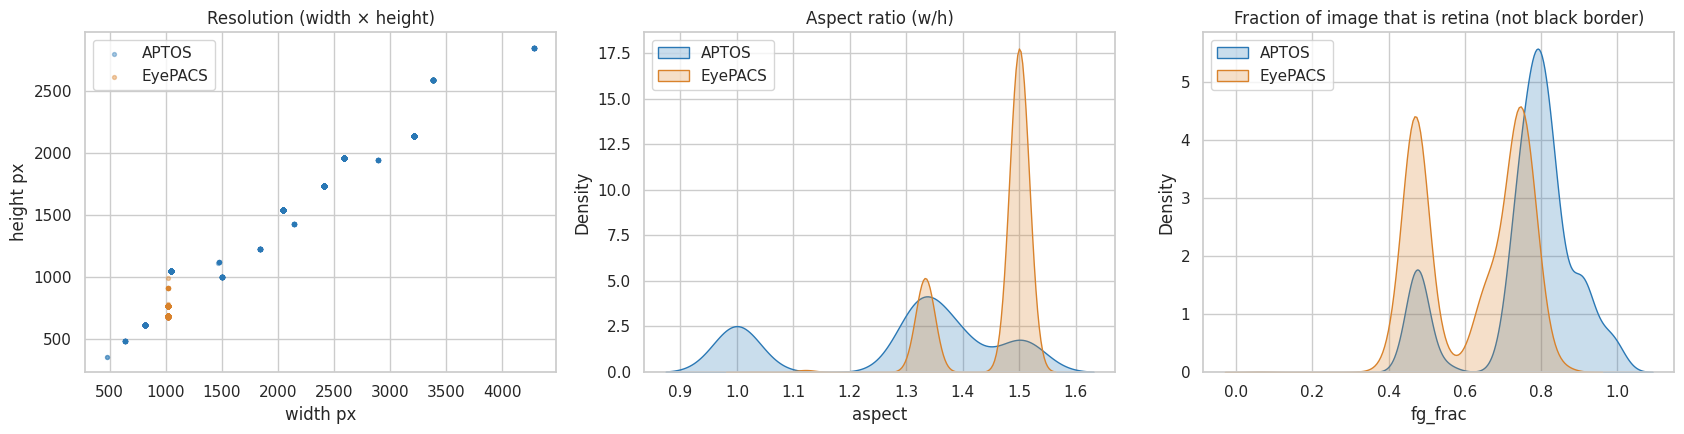

Most common (width, height) pairs:

APTOS:
width  height
1050   1050      398
2416   1736      251
2588   1958      223

EyePACS:
width  height
1024   683       991
       768       332
       679        63


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for src, sub in sample.groupby("source"):
    # Resolution scatter
    axes[0].scatter(sub.width, sub.height, s=8, alpha=0.4, label=src, color=PALETTE[src])

    # Aspect ratio KDE
    if sub.aspect.notna().sum() > 1:
        sns.kdeplot(sub.aspect.dropna(), ax=axes[1], label=src, color=PALETTE[src],
                    fill=True, warn_singular=False)

    # Foreground fraction KDE
    if sub.fg_frac.notna().sum() > 1:
        sns.kdeplot(sub.fg_frac.dropna(), ax=axes[2], label=src, color=PALETTE[src],
                    fill=True, warn_singular=False)

axes[0].set(title="Resolution (width × height)", xlabel="width px", ylabel="height px")
axes[1].set(title="Aspect ratio (w/h)")
axes[2].set(title="Fraction of image that is retina (not black border)")

for a in axes:
    a.legend()

plt.tight_layout()
plt.show()

# Most common resolutions per source (cleaner print)
print("Most common (width, height) pairs:")
for src, sub in sample.groupby("source"):
    top = sub[["width", "height"]].value_counts().head(3)
    print(f"\n{src}:")
    print(top.to_string())

APTOS resolutions vary a lot because the images come from several clinics and cameras. Many are wide, with large black side borders, and some have the top and bottom of the retina cut off. The resized EyePACS images are more uniform. In both datasets a large share of each image is black background, which is pixels and compute spent on nothing. That is the reason for the crop in the next section.

## 4. Sample images per grade

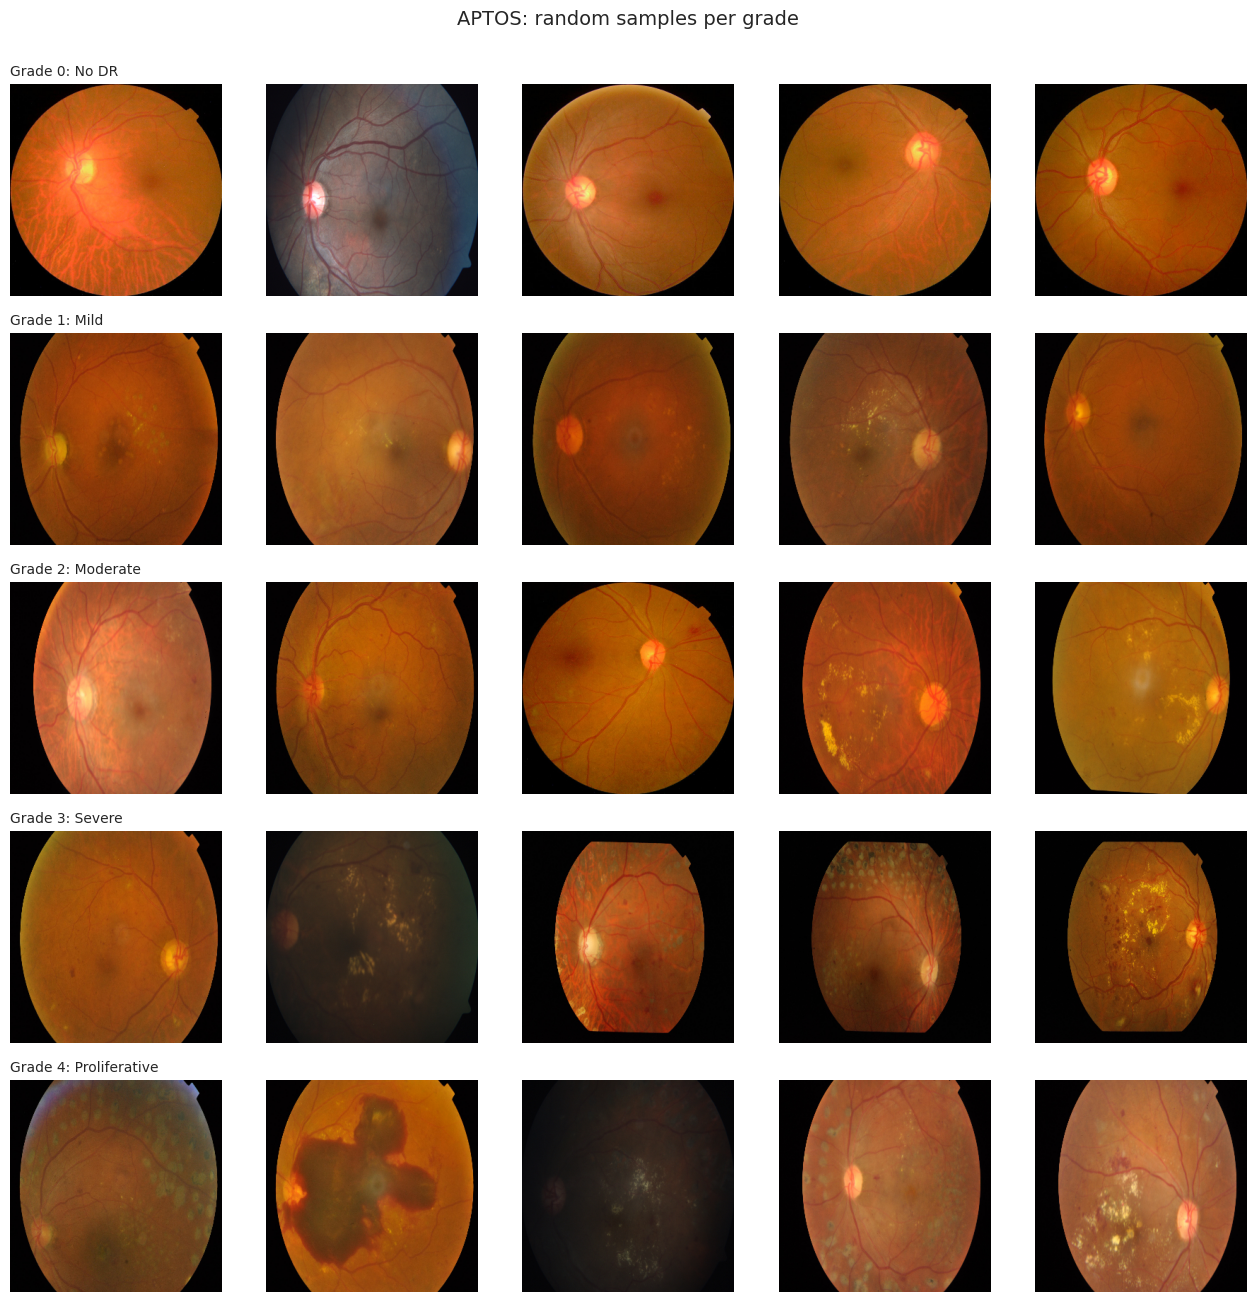

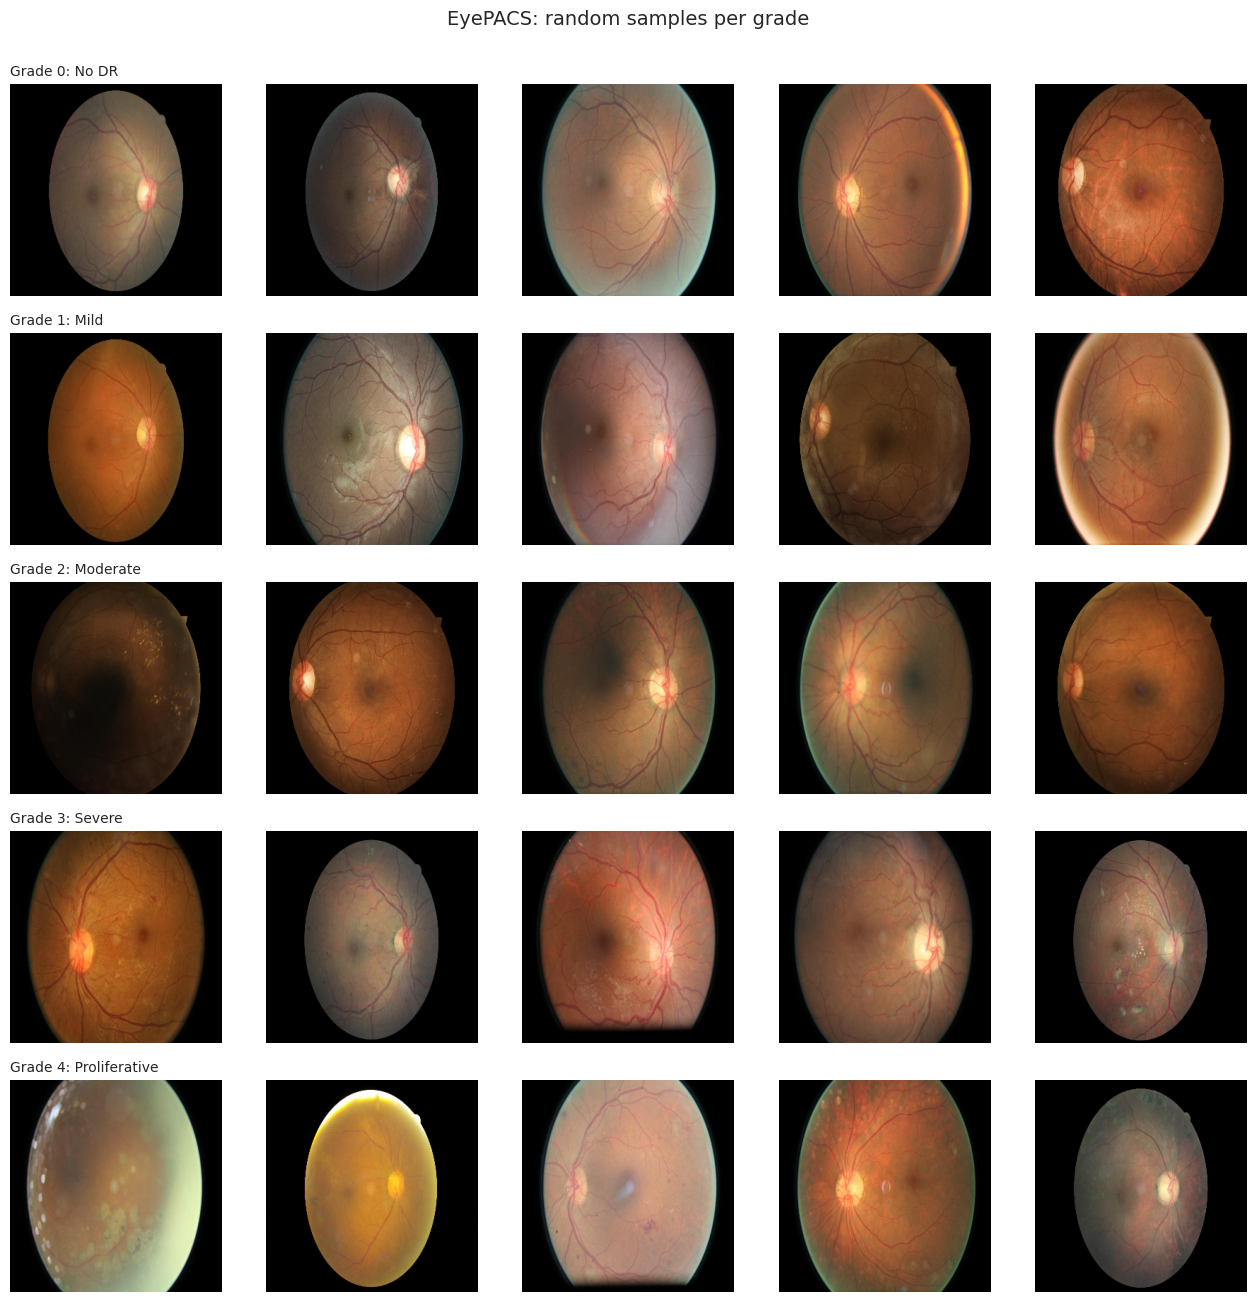

In [14]:
def load_rgb(p, size=None):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size)) if size else img

N_PER = 5
for src, sub in df.groupby("source"):
    fig, axes = plt.subplots(5, N_PER, figsize=(N_PER * 2.6, 5 * 2.6))
    for g in range(5):
        pool = sub[sub.grade == g]
        picks = pool.sample(min(N_PER, len(pool)), random_state=SEED) if len(pool) else pool
        for j in range(N_PER):
            ax = axes[g, j]; ax.axis("off")
            if j < len(picks):
                ax.imshow(load_rgb(picks.iloc[j].path, 300))
            if j == 0:
                ax.set_title(f"Grade {g}: {GRADE_NAMES[g]}", loc="left", fontsize=10)
    plt.suptitle(f"{src}: random samples per grade", fontsize=14, y=1.0); plt.tight_layout(); plt.show()

## 5. Preprocessing: crop the black border

Threshold the grayscale image, keep the bounding box of the retina, then pad to a square. Optionally apply **Ben Graham's** local-contrast normalization (subtract a Gaussian blur), from the 2015 Kaggle winning solution, which evens out lighting differences between cameras.

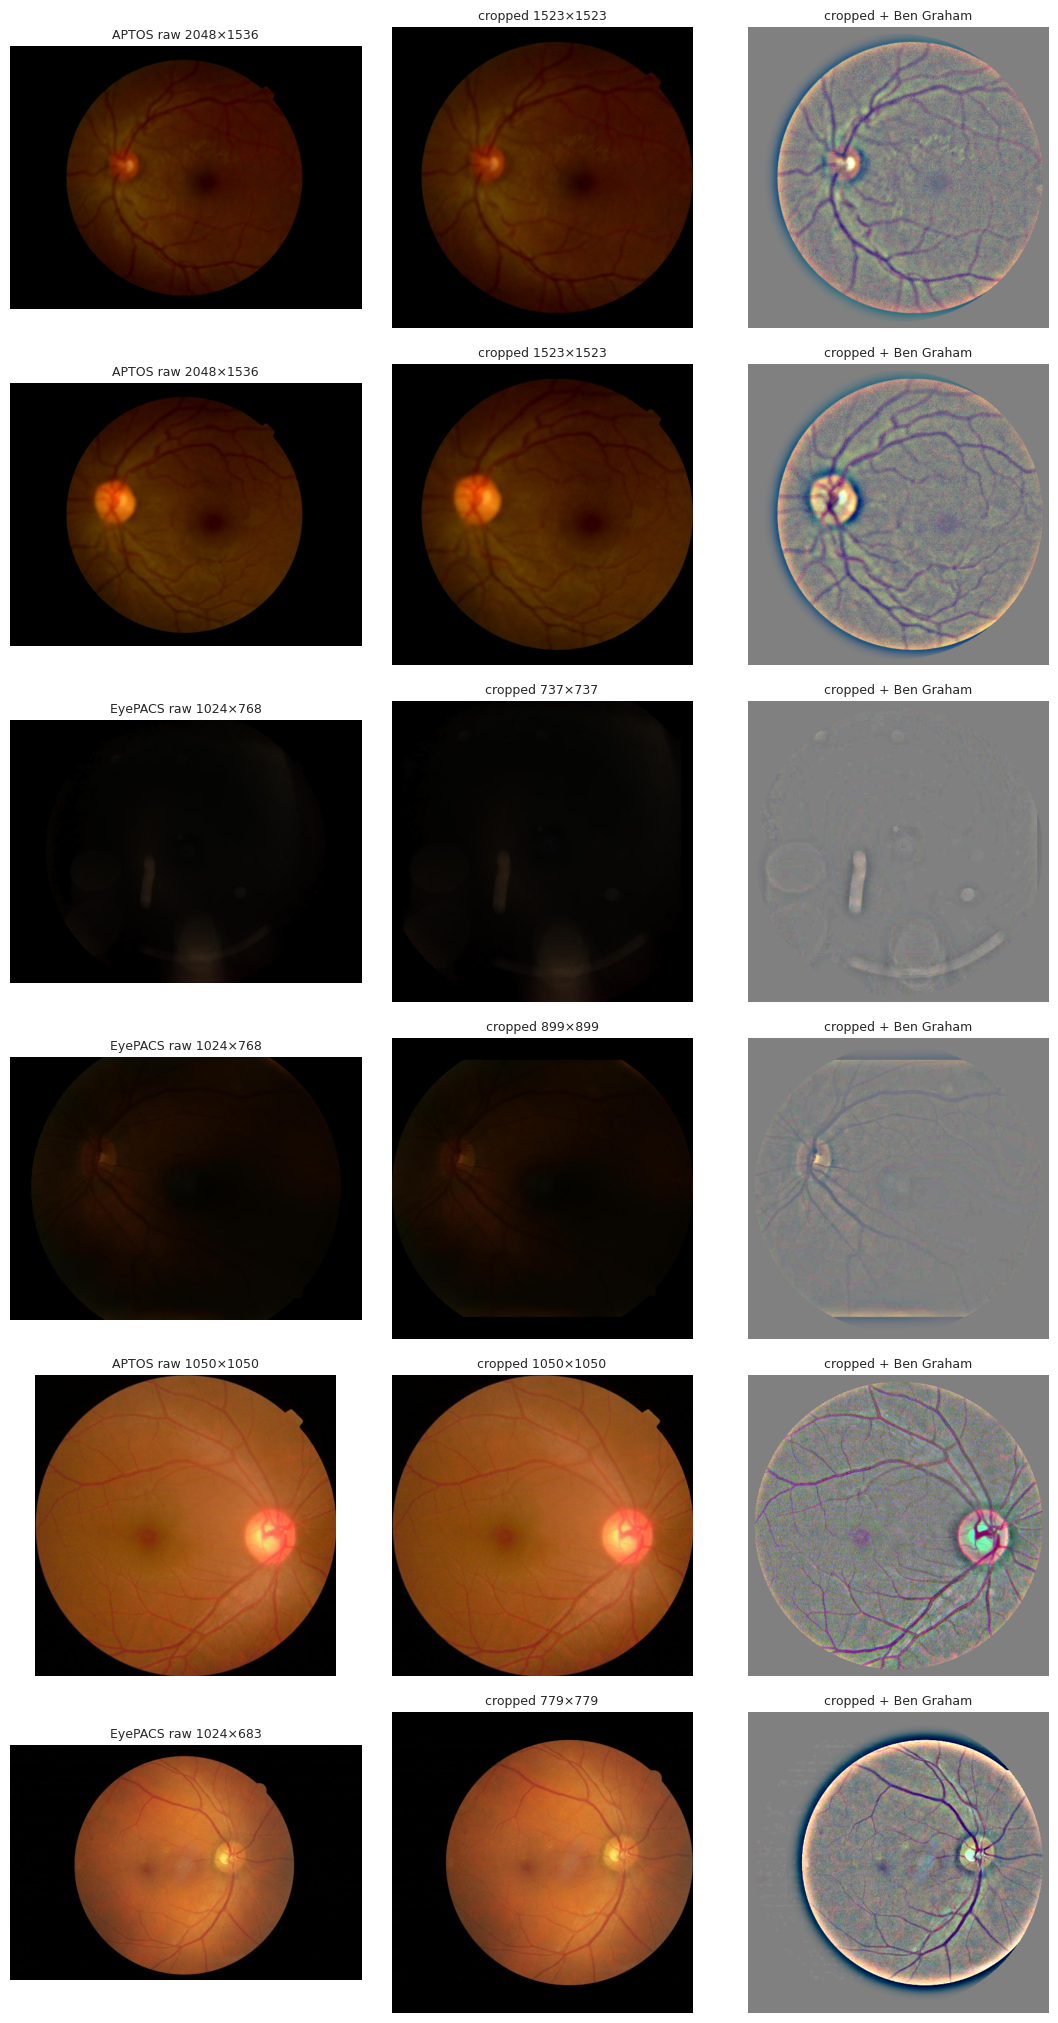

In [15]:
def crop_black_border(img, tol=10, pad_square=True):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if not mask.any():
        return img
    rows, cols = np.where(mask.any(1))[0], np.where(mask.any(0))[0]
    img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    if pad_square:
        h, w = img.shape[:2]; s = max(h, w)
        top, left = (s - h) // 2, (s - w) // 2
        img = cv2.copyMakeBorder(img, top, s - h - top, left, s - w - left, cv2.BORDER_CONSTANT, value=0)
    return img

def ben_graham(img, size=512, sigma=10):
    img = cv2.resize(img, (size, size))
    out = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigma), -4, 128)
    circ = np.zeros_like(img); cv2.circle(circ, (size // 2, size // 2), int(size * 0.48), (1, 1, 1), -1)
    return out * circ + 128 * (1 - circ)

demo = pd.concat([sample[sample.source == s].nsmallest(2, "fg_frac") for s in PALETTE] +
                 [sample[sample.source == s].sample(1, random_state=1) for s in PALETTE])
fig, axes = plt.subplots(len(demo), 3, figsize=(11, 3.4 * len(demo)))
for i, (_, r) in enumerate(demo.iterrows()):
    raw = load_rgb(r.path); crop = crop_black_border(raw)
    for ax, im, t in zip(axes[i], [raw, crop, ben_graham(crop)],
                         [f"{r.source} raw {raw.shape[1]}×{raw.shape[0]}", f"cropped {crop.shape[1]}×{crop.shape[0]}", "cropped + Ben Graham"]):
        ax.imshow(im.astype(np.uint8)); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Brightness and color differences between datasets
Different cameras and clinics give different color profiles. If brightness or color correlates with grade, a model can learn the shortcut instead of the lesions.

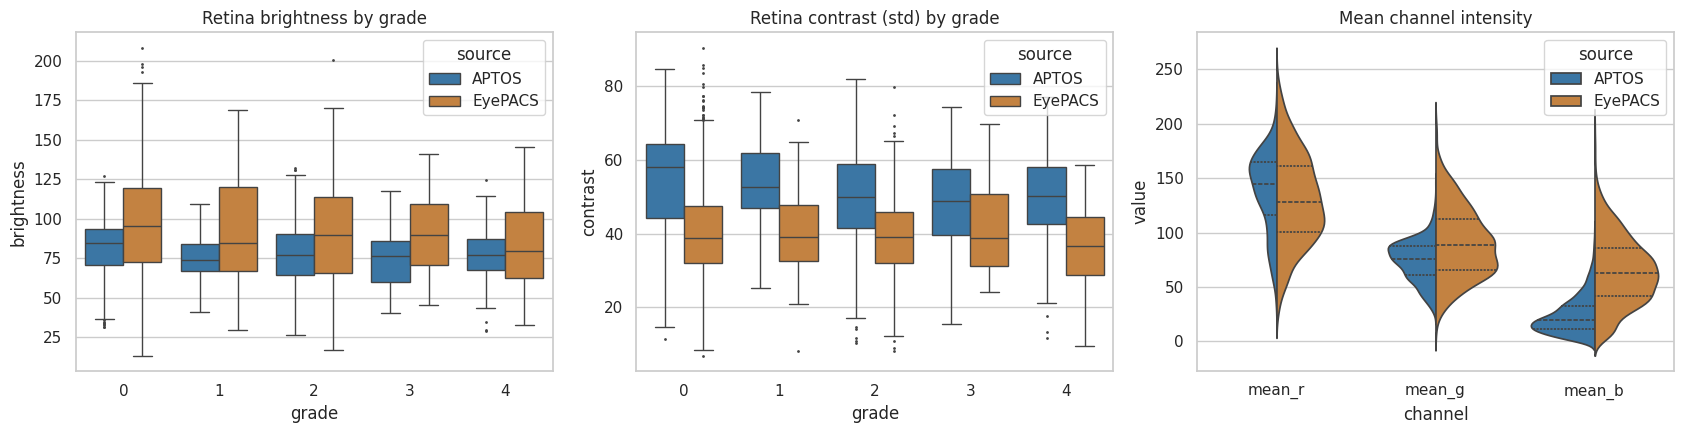

,mean_r,mean_g,mean_b,brightness,contrast
source,,,,,
APTOS,137.9,73.9,23.7,78.5,52.0
EyePACS,130.4,90.6,64.6,95.2,40.1


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=sample, x="grade", y="brightness", hue="source", palette=PALETTE, ax=axes[0], fliersize=1)
sns.boxplot(data=sample, x="grade", y="contrast", hue="source", palette=PALETTE, ax=axes[1], fliersize=1)
ch = sample.melt(id_vars="source", value_vars=["mean_r", "mean_g", "mean_b"], var_name="channel")
sns.violinplot(data=ch, x="channel", y="value", hue="source", palette=PALETTE, split=True, ax=axes[2], inner="quart")
axes[0].set_title("Retina brightness by grade"); axes[1].set_title("Retina contrast (std) by grade"); axes[2].set_title("Mean channel intensity")
plt.tight_layout(); plt.show()
display(sample.groupby("source")[["mean_r", "mean_g", "mean_b", "brightness", "contrast"]].mean().round(1))

In [17]:
# Does file size or resolution predict grade? A strong correlation is a shortcut-learning warning sign.
corr = (sample.groupby("source")
        .apply(lambda d: d[["width", "file_kb", "brightness", "contrast", "blur", "fg_frac"]].corrwith(d.grade, method="spearman"))
        .round(3))
display(corr.style.background_gradient(cmap="RdBu_r", vmin=-.4, vmax=.4).set_caption("Spearman correlation with grade"))

,width,file_kb,brightness,contrast,blur,fg_frac
source,,,,,,
APTOS,0.614000,0.520000,-0.130000,-0.184000,-0.221000,0.117000
EyePACS,nan,-0.061000,-0.093000,-0.021000,-0.115000,0.023000


In APTOS, image width and file size are known to correlate with grade, because different clinics contributed different shares of severe cases. A CNN can partly "grade" from capture conditions. Crop and resize every image to the same square size so that resolution can't leak, and check results across datasets.

## 7. Image quality: blur and underexposure
Low variance of the Laplacian means a blurry image. Very low brightness means an underexposed one. EyePACS is known to contain many images too poor to grade.

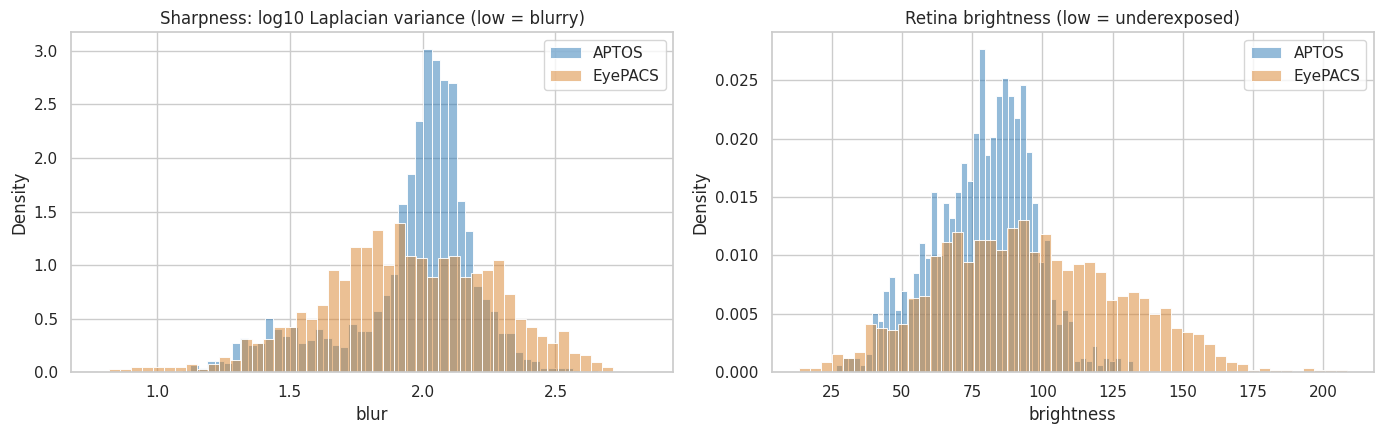

Flagged (bottom 5% sharpness or brightness): blur < 23.7, brightness < 45.1


source,APTOS % flagged,EyePACS % flagged
grade,,
0,8.7,7.8
1,2.6,12.5
2,7.8,14.2
3,5.1,8.1
4,5.8,20.0


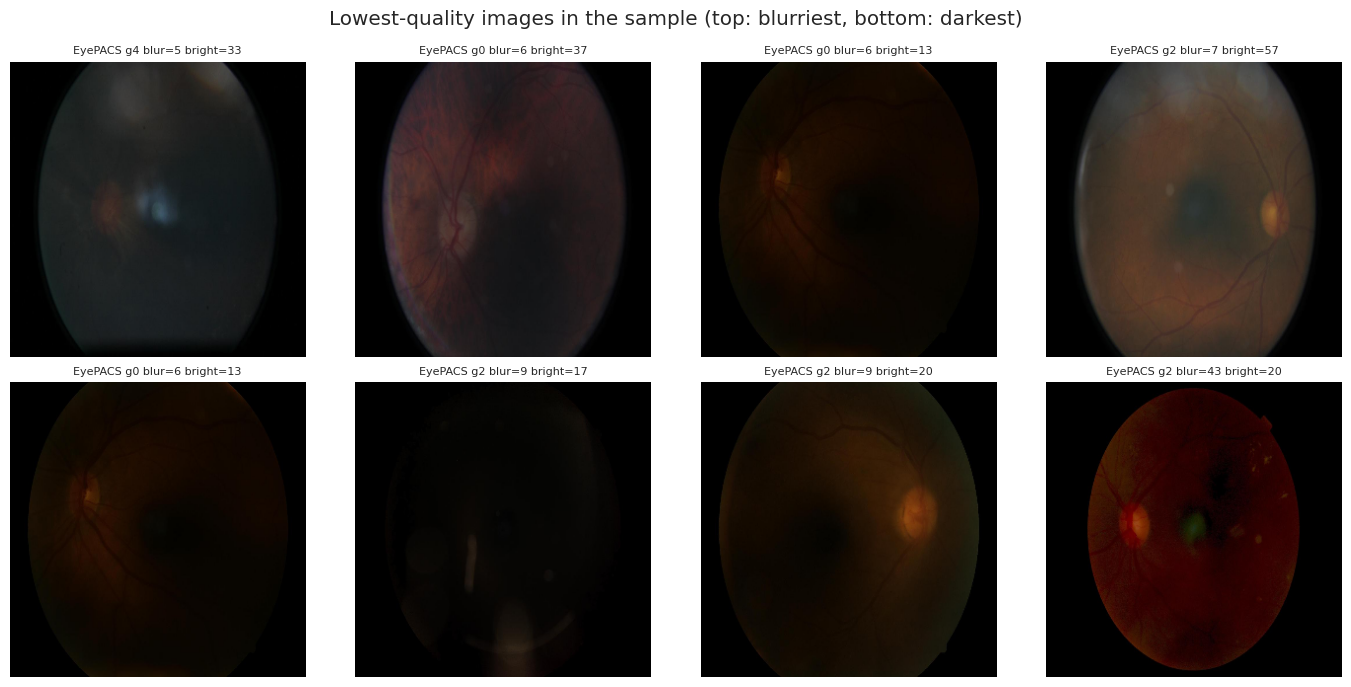

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for src, sub in sample.groupby("source"):
    sns.histplot(np.log10(sub.blur + 1), ax=axes[0], label=src, color=PALETTE[src], stat="density", bins=50, alpha=.5)
    sns.histplot(sub.brightness, ax=axes[1], label=src, color=PALETTE[src], stat="density", bins=50, alpha=.5)
axes[0].set(title="Sharpness: log10 Laplacian variance (low = blurry)"); axes[1].set(title="Retina brightness (low = underexposed)")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

blur_thr = sample.blur.quantile(.05); dark_thr = sample.brightness.quantile(.05)
sample["low_quality"] = (sample.blur < blur_thr) | (sample.brightness < dark_thr)
print(f"Flagged (bottom 5% sharpness or brightness): blur < {blur_thr:.1f}, brightness < {dark_thr:.1f}")
display(sample.groupby(["source", "grade"]).low_quality.mean().unstack(0).mul(100).round(1).rename(columns=lambda c: f"{c} % flagged"))

worst = pd.concat([sample.nsmallest(4, "blur"), sample.nsmallest(4, "brightness")])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(load_rgb(r.path, 300)); ax.axis("off")
    ax.set_title(f"{r.source} g{r.grade} blur={r.blur:.0f} bright={r.brightness:.0f}", fontsize=8)
plt.suptitle("Lowest-quality images in the sample (top: blurriest, bottom: darkest)"); plt.tight_layout(); plt.show()

## 8. EyePACS patient structure: left and right eyes
Each EyePACS patient has two images. The two eyes are strongly correlated, so a random image-level split puts the same patient in both train and validation and inflates scores. **Split by patient.**

Patients: 17,563 | with both eyes: 17,563
Left/right exact grade agreement: 87.2% | within ±1 grade: 95.7%


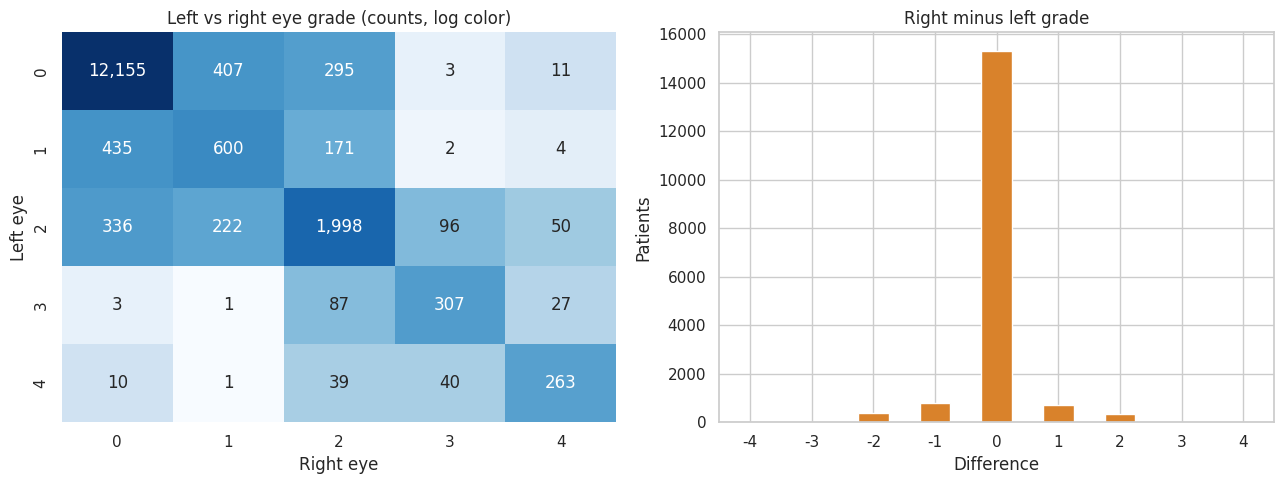

In [19]:
pairs = eyepacs.pivot_table(index="patient_id", columns="eye", values="grade", aggfunc="first").dropna().astype(int)
print(f"Patients: {eyepacs.patient_id.nunique():,} | with both eyes: {len(pairs):,}")
agree = (pairs.left == pairs.right).mean(); within1 = ((pairs.left - pairs.right).abs() <= 1).mean()
print(f"Left/right exact grade agreement: {agree:.1%} | within ±1 grade: {within1:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = pd.crosstab(pairs.left, pairs.right)
sns.heatmap(np.log10(cm + 1), annot=cm, fmt=",", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set(title="Left vs right eye grade (counts, log color)", xlabel="Right eye", ylabel="Left eye")
pairs.assign(diff=pairs.right - pairs.left)["diff"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color=PALETTE["EyePACS"], rot=0)
axes[1].set(title="Right minus left grade", xlabel="Difference", ylabel="Patients")
plt.tight_layout(); plt.show()

Because the two eyes agree so often, a model that sees both eyes of a patient can use the other eye as extra input. That is a common trick in strong EyePACS solutions, and also why patient-level splitting is essential.

## 9. Near-duplicate check (APTOS)
APTOS is known to contain duplicate and near-duplicate images, some with **conflicting grades**. A 64-bit difference hash (dHash) on the cropped image finds them.

Before training: drop near-duplicates whose grades conflict, merge the agreeing ones, and keep every duplicate group on the **same side** of any split.

## 10. Leakage-safe train/validation split
Stratified by grade and grouped by patient (EyePACS) or duplicate cluster (APTOS). The result is saved to `/kaggle/working/dr_splits.csv` for the modelling notebook.

In [26]:
from sklearn.model_selection import StratifiedGroupKFold

# Fallback if the near-duplicates cell (6200ebfb) was deleted
if "dups" not in globals():
    dups = pd.DataFrame(columns=["i", "j", "hamming"])

# Union-find on APTOS (only if dups exist and indices match aptos)
parent = list(range(len(aptos)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

# Only union if dups was built against the original aptos indices
if len(dups) and "i" in dups.columns and dups.i.max() < len(aptos):
    for i, j in zip(dups.i, dups.j):
        pi, pj = find(i), find(j)
        if pi != pj:
            parent[pi] = pj

aptos = aptos.copy()
aptos["group"] = ["aptos_" + str(find(i)) for i in range(len(aptos))]
conflict_groups = aptos.groupby("group").grade.nunique()
conflict_groups = conflict_groups[conflict_groups > 1].index
aptos["drop_conflict"] = aptos.group.isin(conflict_groups)

eyepacs = eyepacs.copy()
eyepacs["group"] = "eyepacs_" + eyepacs.patient_id.astype(str)
eyepacs["drop_conflict"] = False

cols = ["image_id", "patient_id", "eye", "grade", "source", "path", "group", "drop_conflict"]
split = pd.concat([aptos[cols], eyepacs[cols]], ignore_index=True)

split["fold"] = -1
for src, idx in split.groupby("source").groups.items():
    sub = split.loc[idx].copy()
    # Drop conflicting APTOS images from the split (optional; comment out to keep them)
    # sub = sub[~sub.drop_conflict]
    if sub.grade.nunique() < 2 or len(sub) < 5:
        continue
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    try:
        for f, (_, va) in enumerate(sgkf.split(sub, sub.grade, sub.group)):
            split.loc[sub.index[va], "fold"] = f
    except ValueError as e:
        print(f"StratifiedGroupKFold failed for {src}: {e}")
        # Fallback: regular stratified if grouping is too constrained
        from sklearn.model_selection import StratifiedKFold
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        for f, (_, va) in enumerate(skf.split(sub, sub.grade)):
            split.loc[sub.index[va], "fold"] = f

out = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
out.mkdir(exist_ok=True)
split.to_csv(out / "dr_splits.csv", index=False)
print(f"Saved {len(split):,} rows to {out / 'dr_splits.csv'}; "
      f"{int(split.drop_conflict.sum())} APTOS images flagged as conflicting duplicates")

# Fold balance check
print("\nFold × grade distribution (%):")
print(pd.crosstab([split.source, split.fold], split.grade, normalize="index").mul(100).round(1))

Saved 38,788 rows to dr_splits.csv; 0 APTOS images flagged as conflicting duplicates

Fold × grade distribution (%):
grade            0     1     2    3    4
source  fold                            
APTOS   0     50.8  10.4  26.2  4.6  8.0
        1     45.8  11.3  28.2  5.9  8.7
        2     49.6  10.2  28.1  5.2  6.8
        3     52.0   9.0  24.7  5.6  8.6
        4     48.2   9.6  29.1  5.1  8.1
EyePACS 0     73.9   6.6  15.0  2.4  2.0
        1     72.5   6.9  15.5  3.1  1.9
        2     73.6   7.5  14.4  2.5  2.0
        3     74.2   6.8  14.9  2.2  1.9
        4     73.1   6.9  15.5  2.2  2.2


## 11. Summary and next steps

**Findings**
1. **Heavy imbalance.** Grade 0 makes up about half of APTOS and about three-quarters of EyePACS, and grades 3 and 4 are rare. Use **QWK** as the metric and an ordinal or regression loss with tuned rounding thresholds.
2. **The datasets differ.** Resolution, field of view, color and grade mix all differ between APTOS and EyePACS. Normalize inputs (crop, then square resize, optionally Ben Graham) and always report results on each dataset separately.
3. **Black borders waste pixels.** Cropping recovers a large share of the useful resolution, especially in wide APTOS images.
4. **Shortcut risk.** Capture properties such as image size and file size correlate with grade in APTOS. Resize everything to the same size before the model sees it.
5. **Quality.** A noticeable tail of blurry and dark images exists, mainly in EyePACS. Consider filtering them, down-weighting them, or adding a quality-classification side task.
6. **Leakage.** Both eyes of an EyePACS patient, and APTOS near-duplicates, must stay on the same side of a split. That is handled in `dr_splits.csv`.

**Suggested modelling baseline**
- Preprocess: crop the border, resize to 384–512 px, light augmentation (flips, rotation, brightness and contrast).
- Backbone: EfficientNet-B3/B4 or ConvNeXt-T (ImageNet weights), or **RETFound** for a retina-specific starting point.
- Pretrain on EyePACS, fine-tune on APTOS, evaluate on the APTOS validation folds plus an external set such as Messidor-2.